# Лабораторная № 2. Классификация
**Темников Дмитрий Павлович, М8О-306БВ-24**

Предсказываем `Survived`: 1 — пассажир Titanic выжил, 0 — погиб.
[Данные Kaggle](https://www.kaggle.com/datasets/yasserh/titanic-dataset) сохранены в `data/Titanic-Dataset.csv`.
Запускать ячейки сверху вниз из папки `classification`. Зависимости: `pandas`, `matplotlib`, `scikit-learn`.

In [1]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

SEED = 26

## 1. Данные
Проверим размер, типы, пропуски, повторы и баланс классов.

In [2]:
data = pd.read_csv('data/Titanic-Dataset.csv')
print('Размер:', data.shape, 'Полных повторов:', data.duplicated().sum())
display(data.head())
display(pd.DataFrame({'Тип': data.dtypes, 'Пропуски': data.isna().sum()}))
display(data['Survived'].value_counts().sort_index().rename('Количество'))

Размер: (891, 12) Полных повторов: 0


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,Тип,Пропуски
PassengerId,int64,0
Survived,int64,0
Pclass,int64,0
Name,str,0
Sex,str,0
Age,float64,177
SibSp,int64,0
Parch,int64,0
Ticket,str,0
Fare,float64,0


Survived
0    549
1    342
Name: Количество, dtype: int64

В данных 891 пассажир: 549 погибших и 342 выживших. Классы несбалансированы, полных повторов нет.
Пропущены 177 значений `Age`, 687 — `Cabin` и 2 — `Embarked`.

Удалим `PassengerId`, `Name`, `Ticket`: это идентификатор, имя и номер билета, которые могут способствовать запоминанию пассажиров или групп.
Удалим `Cabin` из-за большого числа пропусков. `Survived` используем только как ответ.
Оставляем признаки, известные до катастрофы. Делим данные 80/20 с сохранением долей классов.

Train: 712 Test: 179


,Pclass,Age,SibSp,Parch,Fare
count,712.00,579.00,712.00,712.00,712.00
mean,2.30,29.57,0.53,0.39,32.55
std,0.84,14.24,1.05,0.82,51.40
min,1.00,0.67,0.00,0.00,0.00
25%,2.00,20.00,0.00,0.00,7.92
50%,3.00,28.00,0.00,0.00,14.50
75%,3.00,38.00,1.00,0.00,30.50
max,3.00,80.00,8.00,6.00,512.33


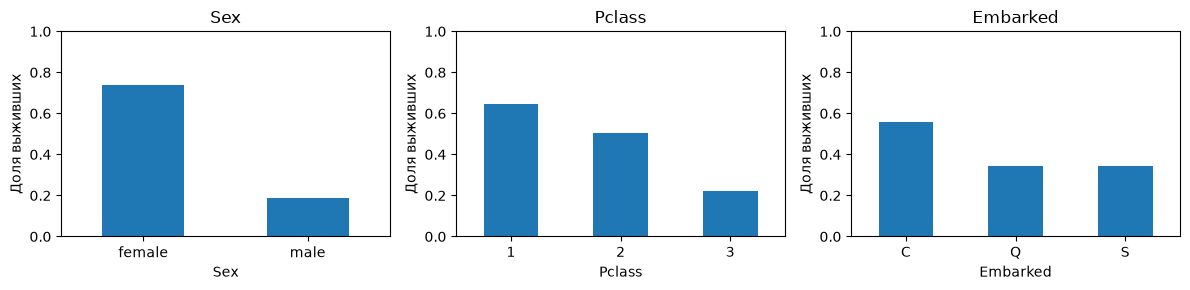

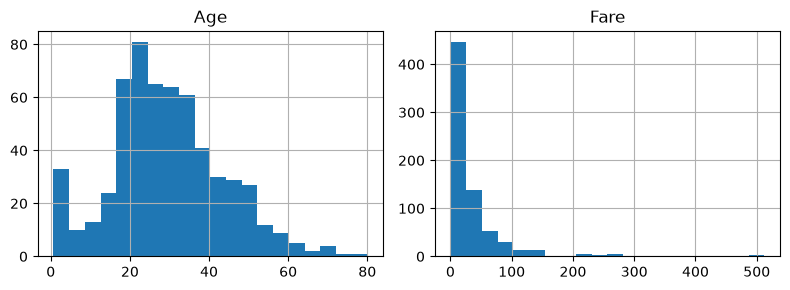

In [3]:
X = data.drop(columns=['Survived', 'PassengerId', 'Name', 'Ticket', 'Cabin'])
y = data['Survived']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
print('Train:', len(X_train), 'Test:', len(X_test))

train = X_train.assign(Survived=y_train)
display(X_train.describe().round(2))
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for column, ax in zip(['Sex', 'Pclass', 'Embarked'], axes):
    train.groupby(column)['Survived'].mean().plot.bar(ax=ax, title=column, rot=0)
    ax.set(ylabel='Доля выживших', ylim=(0, 1))
plt.tight_layout()
plt.show()
X_train[['Age', 'Fare']].hist(bins=20, figsize=(8, 3))
plt.tight_layout()
plt.show()

На train доля выживших выше среди женщин и пассажиров первого класса.
Возраст и стоимость билета имеют разные масштабы; у стоимости есть длинный правый хвост.
Это реальные возможные значения, поэтому без дополнительных оснований их не удаляем.

## 2. Подготовка и модели
Числовые пропуски заменяем медианой: она устойчива к большим значениям.
Категориальные — самым частым значением; категории кодируем One-Hot, чтобы не задавать им числовое расстояние.
`Pclass` тоже считаем категорией. Новые категории при проверке игнорируем.

Для SVM и KNN стандартизируем числовые признаки: иначе `Fare` может доминировать в расстояниях.
Деревья делят значения по порогам, поэтому масштабирование им не нужно.
Все преобразования обучаются внутри Pipeline только на train, в том числе на каждом фолде CV.

In [4]:
numeric = ['Age', 'SibSp', 'Parch', 'Fare']
categorical = ['Pclass', 'Sex', 'Embarked']

def preprocess(scale=False):
    steps = [SimpleImputer(strategy='median')]
    if scale:
        steps.append(StandardScaler())
    return ColumnTransformer([
        ('num', make_pipeline(*steps), numeric),
        ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'),
                             OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
         categorical)
    ], verbose_feature_names_out=False)

models = {
    'Baseline': make_pipeline(preprocess(), DummyClassifier(strategy='most_frequent')),
    'Decision Tree': make_pipeline(preprocess(), DecisionTreeClassifier(
        max_depth=4, min_samples_leaf=5, random_state=SEED)),
    'Random Forest': make_pipeline(preprocess(), RandomForestClassifier(
        n_estimators=200, max_depth=6, min_samples_leaf=2, random_state=SEED)),
    'Gradient Boosting': make_pipeline(preprocess(), GradientBoostingClassifier(
        n_estimators=100, max_depth=2, random_state=SEED)),
    'SVM': make_pipeline(preprocess(scale=True), SVC()),
    'KNN': make_pipeline(preprocess(scale=True), KNeighborsClassifier(n_neighbors=7))
}

Baseline всем предсказывает самый частый класс — 0.
Дерево строит последовательность условий; лес усредняет прогнозы деревьев;
бустинг последовательно исправляет ошибки ансамбля. SVM ищет разделяющую границу,
KNN голосует по семи ближайшим соседям.

Главная метрика — **F1 для класса 1**: гармоническое среднее Precision и Recall.
Precision — доля выживших среди предсказанных выживших, Recall — доля найденных выживших.
Accuracy — доля всех верных ответов. F1 полезнее одной Accuracy при дисбалансе классов.
Если модель никого не относит к классу 1, его Precision и F1 принимаем равными 0.

Настройки фиксируем заранее. Для выбора модели используем средний F1 на трёх одинаковых
стратифицированных фолдах train. Test открываем только после выбора.

In [5]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
cv_rows = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv,
                            scoring='f1', return_train_score=True)
    cv_rows.append({'Model': name, 'Train F1 (CV)': scores['train_score'].mean(),
                    'CV F1': scores['test_score'].mean()})
cv_table = pd.DataFrame(cv_rows).set_index('Model')
display(cv_table.round(3))
best_name = cv_table['CV F1'].idxmax()
print('Выбрана по CV:', best_name)

,Train F1 (CV),CV F1
Model,,
Baseline,0.000,0.000
Decision Tree,0.756,0.694
Random Forest,0.842,0.727
Gradient Boosting,0.845,0.746
SVM,0.780,0.764
KNN,0.795,0.731


Выбрана по CV: SVM


## 3. Финальная оценка
Все модели учим на одном train и проверяем на одном test.
Порог задания — строго **F1 > 0.70**. Общий тест группы не предоставлен,
поэтому ниже оценивается только наше локальное разбиение.

,Accuracy,Precision,Recall,F1,Train F1,F1 > 0.70
Model,,,,,,
Baseline,0.615,0.000,0.000,0.000,0.000,False
Decision Tree,0.821,0.814,0.696,0.750,0.772,True
Random Forest,0.816,0.821,0.667,0.736,0.807,True
Gradient Boosting,0.821,0.825,0.681,0.746,0.821,True
SVM,0.810,0.797,0.681,0.734,0.781,True
KNN,0.782,0.750,0.652,0.698,0.791,False


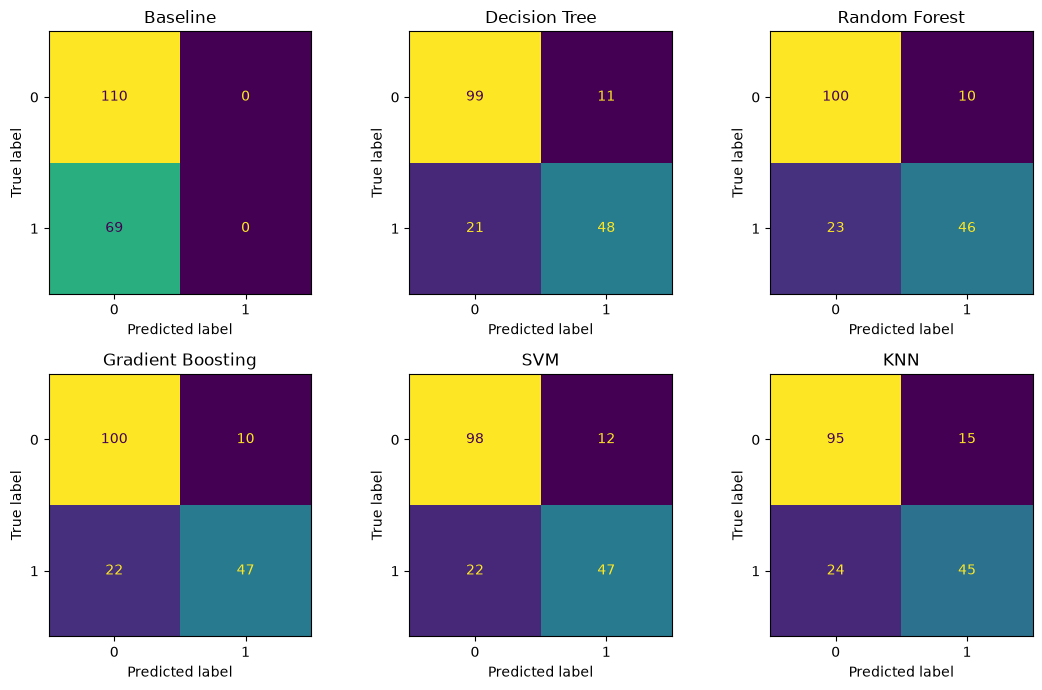

In [6]:
rows, predictions = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    rows.append({'Model': name, 'Accuracy': accuracy_score(y_test, pred),
                 'Precision': precision_score(y_test, pred, zero_division=0),
                 'Recall': recall_score(y_test, pred, zero_division=0),
                 'F1': f1_score(y_test, pred),
                 'Train F1': f1_score(y_train, model.predict(X_train))})
results = pd.DataFrame(rows).set_index('Model')
results['F1 > 0.70'] = results['F1'] > 0.70
display(results.round(3))

fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for (name, pred), ax in zip(predictions.items(), axes.flat):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

Дерево получило Train F1 = 0.772 и Test F1 = 0.750: разрыв небольшой.
На CV разрыв заметнее (0.756 против 0.694), поэтому признаки переобучения есть.
У леса и бустинга train также лучше test. Ограниченная глубина сдерживает сложность деревьев.

На test дерево оказалось первым (F1 = 0.750), бустинг немного опередил лес (0.746 против 0.736).
SVM выбран заранее по CV (0.764); его Test F1 = 0.734. По результатам test выбор не меняем.
Все обученные модели лучше baseline, но KNN с F1 = 0.698 не прошёл порог 0.70.
Нелинейные модели учитывают сочетания признаков; KNN чувствителен к соседям и редким категориям.
Различия на 179 пассажирах могут зависеть от случайного разбиения.

В матрицах строки — истинный класс, столбцы — предсказанный.
**FP**: погибшего ошибочно сочли выжившим; **FN**: выжившего ошибочно сочли погибшим.
Baseline пропускает всех выживших, поэтому его F1 = 0, хотя Accuracy больше половины.

## 4. Важность признаков
Важность показывает суммарный вклад разбиений по признаку в уменьшение нечистоты
(у бустинга — ошибки его деревьев). Сумма важностей внутри модели равна 1.
One-Hot категории показаны отдельно. Это характеристика модели, а не доказательство причины выживания;
связанные признаки могут делить важность.

Decision Tree — top-3: Sex_female, Pclass_3, Age
Random Forest — top-3: Sex_male, Sex_female, Fare
Gradient Boosting — top-3: Sex_female, Sex_male, Pclass_3


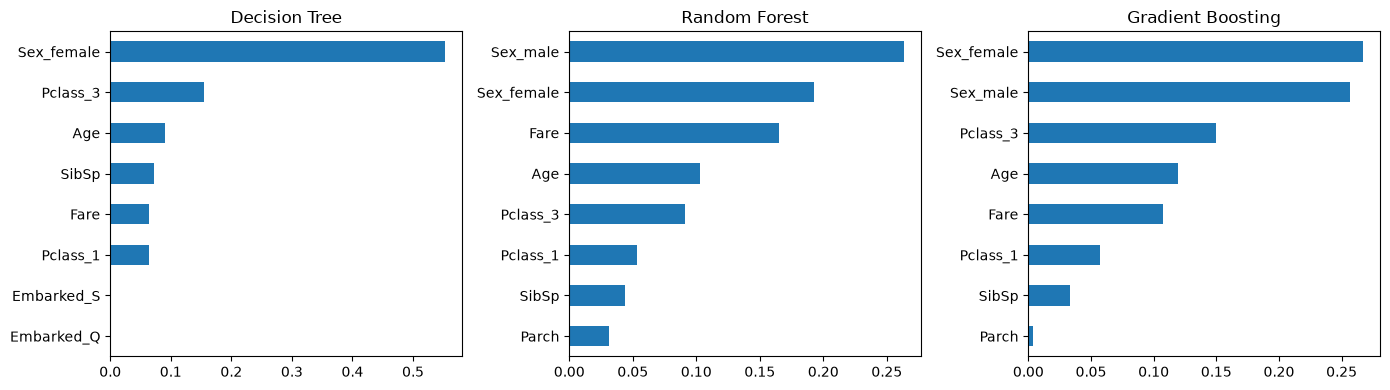

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for name, ax in zip(['Decision Tree', 'Random Forest', 'Gradient Boosting'], axes):
    model = models[name]
    importance = pd.Series(model[-1].feature_importances_,
                           index=model[0].get_feature_names_out()).sort_values()
    importance.tail(8).plot.barh(ax=ax, title=name)
    print(name, '— top-3:', ', '.join(importance.nlargest(3).index))
plt.tight_layout()
plt.show()

У всех трёх моделей важен пол. У дерева и бустинга в top-3 входит третий класс,
у дерева также возраст, у леса — стоимость билета. Это согласуется с EDA по полу и классу;
стоимость связана с условиями поездки. One-Hot столбцы одного признака могут делить важность,
поэтому их отдельные места в рейтинге нельзя трактовать как независимые факторы.
Причинный эффект эти наблюдательные данные не устанавливают.

## 5. Ошибки выбранной по CV модели
Сравним FP и FN, затем частоту ошибок по полу и классу билета.
Размер группы важен: доли на небольшом числе пассажиров менее устойчивы.

In [8]:
pred = predictions[best_name]
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(f'{best_name}: TN={tn}, FP={fp}, FN={fn}, TP={tp}')
errors = X_test.assign(real=y_test, prediction=pred)
errors['error'] = errors['real'] != errors['prediction']
for column in ['Sex', 'Pclass']:
    display(errors.groupby(column)['error'].agg(Count='size', Errors='sum', Rate='mean').round(3))
display(errors.loc[errors['error'],
                   ['Sex', 'Pclass', 'Age', 'Fare', 'real', 'prediction']].head(5))

SVM: TN=98, FP=12, FN=22, TP=47


,Count,Errors,Rate
Sex,,,
female,61,12,0.197
male,118,22,0.186


,Count,Errors,Rate
Pclass,,,
1,41,8,0.195
2,37,2,0.054
3,101,24,0.238


,Sex,Pclass,Age,Fare,real,prediction
569,male,3,32.0,7.8542,1,0
604,male,1,35.0,26.5500,1,0
509,male,3,26.0,56.4958,1,0
41,female,2,27.0,21.0000,0,1
438,male,1,64.0,263.0000,0,1


Ошибки возможны даже при похожих возрасте, поле и классе: в данных нет положения пассажира
в момент катастрофы, доступа к шлюпке и многих других обстоятельств.
Пропущенный возраст заменяется общей медианой и тоже может ухудшать прогноз.

Идентификатор, имя, билет и каюта исключены до обучения; целевой признак в X отсутствует.
Препроцессинг не видит test при обучении. Это исключает прямую утечку через эти столбцы,
но связанные пассажиры могут попасть в разные части случайного разбиения:
оценка для совершенно новых семей может отличаться.

У выбранного SVM больше FN (22), чем FP (12): он чаще пропускает выживших,
чем ошибочно обещает выживание погибшим. Самая высокая доля ошибок — в третьем классе:
24 из 101 (23.8%); во втором классе — 2 из 37 (5.4%). По полу доли близки: 19.7% и 18.6%.

Например, пассажиры 569, 604 и 509 — выжившие мужчины, которых модель отнесла к погибшим;
она могла опереться на общую низкую выживаемость мужчин. Пассажирка 41 погибла,
но получила прогноз 1 — общая закономерность для женщин не описывает все случаи.
Пассажир 438 погиб несмотря на первый класс и дорогой билет. Это возможные объяснения,
а не доказанные причины отдельных прогнозов.

## 6. Вывод
- Выполнены обработка пропусков, кодирование категорий и масштабирование для SVM/KNN.
- По CV выбран SVM; его локальный F1 = **0.734**, выше порога **0.70**.
- Дерево, лес и бустинг тоже прошли локальный порог. KNN — нет.
- Пол и класс полезны для прогноза, но не определяют исход каждого пассажира.
- Для результата leaderboard нужна отдельная общая тестовая выборка группы.